# RQ3: Home Mobility Clustering

This notebook identifies home mobility profiles from smartphone-derived features. K-means and GMM are fitted without clinical labels. Final Classification is joined only afterward for post hoc comparison.

In [1]:
from itertools import permutations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency, fisher_exact

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'Clustering':
    PROJECT_ROOT = PROJECT_ROOT.parents[1]

HOME_FEATURES_PATH = PROJECT_ROOT / 'Data/Clustering/Home/home_participant_features.csv'
HOME_ASSIGNMENTS_PATH = PROJECT_ROOT / 'Data/Clustering/Home/home_cluster_assignments.csv'
FINAL_CLASSIFICATION_PATH = PROJECT_ROOT / 'Data/lab/4 Test Classification(4 Test Classification).csv'

FEATURE_COLUMNS = [
    'median_walk_duration',
    'walk_cadence_steps_min',
    'median_mean_step_time',
    'pooled_median_turn_duration_s',
    'pooled_median_turn_step_count',
    'median_sit_to_stand_duration',
]
FEATURE_LABELS = {
    'median_walk_duration': 'Walking duration (s)',
    'walk_cadence_steps_min': 'Walking cadence (steps/min)',
    'median_mean_step_time': 'Walking mean step time (s)',
    'pooled_median_turn_duration_s': 'Pooled turn duration (s)',
    'pooled_median_turn_step_count': 'Pooled turn step count',
    'median_sit_to_stand_duration': 'Sit-to-stand duration (s)',
}
RANDOM_STATE = 42
N_CLUSTERS = 2


In [2]:
home = pd.read_csv(HOME_FEATURES_PATH)
home_analysis = home[['subject_id', 'n_valid_days', *FEATURE_COLUMNS]].dropna(subset=FEATURE_COLUMNS).copy()
home_matrix = home_analysis[FEATURE_COLUMNS]

print(f'Home participants used: {len(home_analysis)}')
print(f'Valid home days per participant: {int(home_analysis.n_valid_days.min())} to {int(home_analysis.n_valid_days.max())}')
display(home_analysis[['subject_id', 'n_valid_days']].sort_values('subject_id'))


Home participants used: 12
Valid home days per participant: 14 to 14


,subject_id,n_valid_days
0,SRS01,14
1,SRS02,14
2,SRS03,14
3,SRS04,14
4,SRS05,14
5,SRS08,14
6,SRS09,14
7,SRS10,14
8,SRS11,14
9,SRS15,14


In [3]:
scaler = StandardScaler()
home_scaled = scaler.fit_transform(home_matrix)

kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=100, random_state=RANDOM_STATE)
kmeans_cluster = kmeans.fit_predict(home_scaled)
gmm = GaussianMixture(
    n_components=N_CLUSTERS,
    covariance_type='diag',
    reg_covar=0.10,
    n_init=100,
    random_state=RANDOM_STATE,
).fit(home_scaled)
gmm_probabilities = gmm.predict_proba(home_scaled)
gmm_cluster = gmm_probabilities.argmax(axis=1)

assignments = pd.DataFrame({
    'subject_id': home_analysis['subject_id'].to_numpy(),
    'n_valid_days': home_analysis['n_valid_days'].to_numpy(),
    'kmeans_cluster': kmeans_cluster,
    'gmm_cluster': gmm_cluster,
    'gmm_membership_probability': gmm_probabilities.max(axis=1),
}).sort_values('subject_id')
assignments.to_csv(HOME_ASSIGNMENTS_PATH, index=False)
display(assignments)


,subject_id,n_valid_days,kmeans_cluster,gmm_cluster,gmm_membership_probability
0,SRS01,14,1,1,1.000000
1,SRS02,14,1,1,1.000000
2,SRS03,14,1,1,1.000000
3,SRS04,14,1,1,1.000000
4,SRS05,14,0,0,0.999999
5,SRS08,14,1,1,1.000000
6,SRS09,14,0,1,0.999924
7,SRS10,14,0,0,0.999893
8,SRS11,14,0,0,0.999998
9,SRS15,14,1,1,0.999993


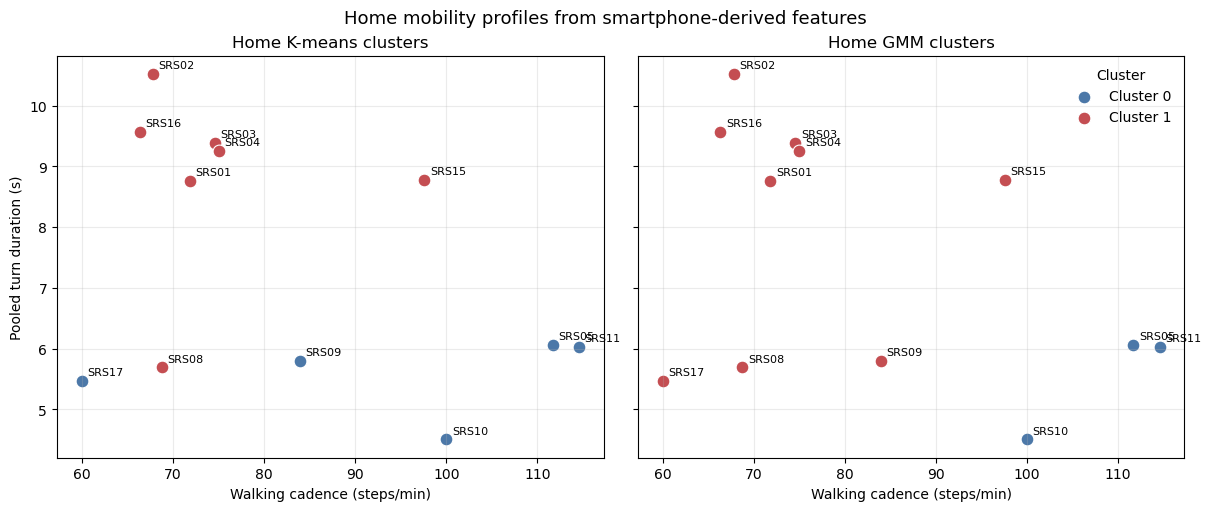

In [4]:
plot_data = home_analysis[['subject_id', 'walk_cadence_steps_min', 'pooled_median_turn_duration_s']].copy()
plot_data['kmeans_cluster'] = kmeans_cluster
plot_data['gmm_cluster'] = gmm_cluster

cluster_colors = {0: '#4C78A8', 1: '#C44E52'}
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, constrained_layout=True)
plot_specs = [
    ('kmeans_cluster', 'Home K-means clusters'),
    ('gmm_cluster', 'Home GMM clusters'),
]
for axis, (cluster_column, title) in zip(axes, plot_specs):
    for cluster, color in cluster_colors.items():
        subset = plot_data[plot_data[cluster_column] == cluster]
        axis.scatter(
            subset['walk_cadence_steps_min'],
            subset['pooled_median_turn_duration_s'],
            s=85,
            color=color,
            edgecolor='white',
            linewidth=0.8,
            label=f'Cluster {cluster}',
        )
        for row in subset.itertuples():
            axis.annotate(
                row.subject_id,
                (row.walk_cadence_steps_min, row.pooled_median_turn_duration_s),
                xytext=(4, 4),
                textcoords='offset points',
                fontsize=8,
            )
    axis.set_title(title)
    axis.set_xlabel('Walking cadence (steps/min)')
    axis.grid(alpha=0.25)
axes[0].set_ylabel('Pooled turn duration (s)')
axes[1].legend(title='Cluster', frameon=False, loc='best')
fig.suptitle('Home mobility profiles from smartphone-derived features', fontsize=13)
plt.show()


## Post Hoc Comparison With Final Classification

Final Classification is introduced only after home clustering is complete. Cluster labels are mapped to the majority Final Classification group for readable confusion matrices; this mapping does not alter the fitted K-means or GMM models.

In [5]:
final_labels = pd.read_csv(FINAL_CLASSIFICATION_PATH)[['Participant ID', 'Final Classification']].dropna()
final_labels = final_labels.drop_duplicates('Participant ID').rename(columns={
    'Participant ID': 'subject_id',
    'Final Classification': 'final_classification',
})
classification_data = assignments.merge(final_labels, on='subject_id', how='inner')
final_codes = classification_data['final_classification'].map({'Non-Faller': 0, 'Faller': 1}).to_numpy()
kmeans_final_contingency = pd.crosstab(classification_data['kmeans_cluster'], final_codes).reindex(
    index=range(N_CLUSTERS), columns=range(N_CLUSTERS), fill_value=0
)
gmm_final_contingency = pd.crosstab(classification_data['gmm_cluster'], final_codes).reindex(
    index=range(N_CLUSTERS), columns=range(N_CLUSTERS), fill_value=0
)

def align_to_final_classification(cluster_labels):
    best_mapping = None
    best_agreement = -1
    for permutation in permutations(range(N_CLUSTERS)):
        mapping = dict(enumerate(permutation))
        aligned = pd.Series(cluster_labels).map(mapping).to_numpy()
        agreement = (aligned == final_codes).mean()
        if agreement > best_agreement:
            best_mapping = mapping
            best_agreement = agreement
    return pd.Series(cluster_labels).map(best_mapping).to_numpy()

classification_data['kmeans_profile'] = align_to_final_classification(classification_data['kmeans_cluster'])
classification_data['gmm_profile'] = align_to_final_classification(classification_data['gmm_cluster'])

def classification_statistics(profile_labels):
    contingency = pd.crosstab(profile_labels, final_codes).reindex(
        index=range(N_CLUSTERS), columns=range(N_CLUSTERS), fill_value=0
    )
    _, fisher_p_value = fisher_exact(contingency.to_numpy())
    chi_square, _, _, _ = chi2_contingency(contingency.to_numpy(), correction=False)
    return {
        'contingency': contingency,
        'fisher_p_value': fisher_p_value,
        'phi': (chi_square / len(classification_data)) ** 0.5,
        'agreement': (profile_labels == final_codes).mean() * 100,
    }

kmeans_final = classification_statistics(classification_data['kmeans_profile'].to_numpy())
gmm_final = classification_statistics(classification_data['gmm_profile'].to_numpy())

final_classification_statistics = pd.DataFrame([
    {
        'Model': 'K-means',
        'Participants': len(classification_data),
        "Fisher's exact test": f"p = {kmeans_final['fisher_p_value']:.3f}",
        'Phi correlation coefficient': f"{kmeans_final['phi']:.3f}",
        'Agreement': f"{kmeans_final['agreement']:.1f}%",
    },
    {
        'Model': 'GMM',
        'Participants': len(classification_data),
        "Fisher's exact test": f"p = {gmm_final['fisher_p_value']:.3f}",
        'Phi correlation coefficient': f"{gmm_final['phi']:.3f}",
        'Agreement': f"{gmm_final['agreement']:.1f}%",
    },
])
display(final_classification_statistics)

home_participant_classification = classification_data[[
    'subject_id', 'final_classification', 'kmeans_cluster', 'gmm_cluster'
]].rename(columns={
    'subject_id': 'Participant',
    'final_classification': 'Final Classification',
    'kmeans_cluster': 'K-means cluster',
    'gmm_cluster': 'GMM cluster',
}).sort_values('Participant').reset_index(drop=True)
display(home_participant_classification)


,Model,Participants,Fisher's exact test,Phi correlation coefficient,Agreement
0,K-means,11,p = 0.545,0.311,63.6%
1,GMM,11,p = 0.236,0.463,63.6%


,Participant,Final Classification,K-means cluster,GMM cluster
0,SRS02,Non-Faller,1,1
1,SRS03,Faller,1,1
2,SRS04,Non-Faller,1,1
3,SRS05,Non-Faller,0,0
4,SRS08,Non-Faller,1,1
5,SRS09,Non-Faller,0,1
6,SRS10,Non-Faller,0,0
7,SRS11,Non-Faller,0,0
8,SRS15,Faller,1,1
9,SRS16,Faller,1,1


### Home K-means clusters and final classification

Final classification was not used to form the clusters. This heatmap is a post hoc comparison.

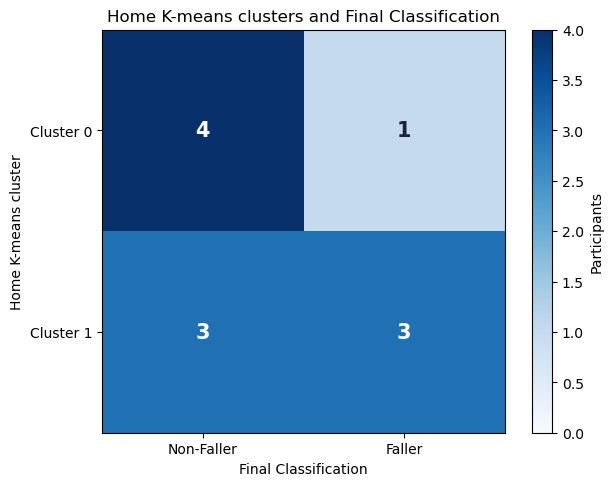

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.75), constrained_layout=True)
matrix = kmeans_final_contingency.to_numpy()
image = ax.imshow(matrix, cmap='Blues', vmin=0)

ax.set_xticks(range(N_CLUSTERS), ['Non-Faller', 'Faller'])
ax.set_yticks(range(N_CLUSTERS), ['Cluster 0', 'Cluster 1'])
ax.set_xlabel('Final Classification')
ax.set_ylabel('Home K-means cluster')
ax.set_title('Home K-means clusters and Final Classification')

for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        value = matrix[row, column]
        ax.text(column, row, str(value), ha='center', va='center',
                color='white' if value >= matrix.max() / 2 else '#1d2630',
                fontsize=15, fontweight='semibold')

fig.colorbar(image, ax=ax, label='Participants')
plt.show()


### Home GMM clusters and final classification

The same post hoc comparison is shown for the Gaussian mixture model.

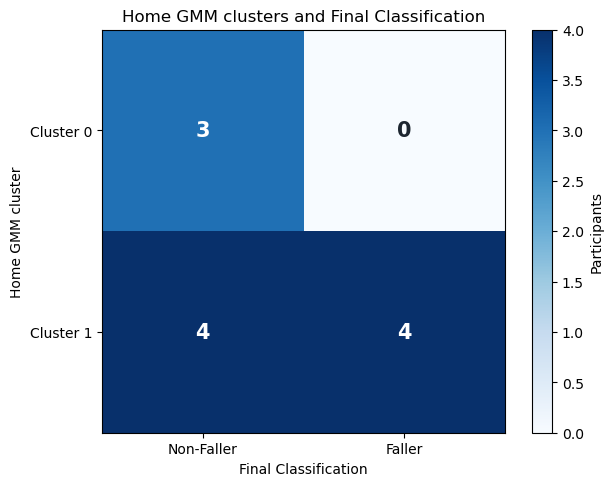

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.75), constrained_layout=True)
matrix = gmm_final_contingency.to_numpy()
image = ax.imshow(matrix, cmap='Blues', vmin=0)

ax.set_xticks(range(N_CLUSTERS), ['Non-Faller', 'Faller'])
ax.set_yticks(range(N_CLUSTERS), ['Cluster 0', 'Cluster 1'])
ax.set_xlabel('Final Classification')
ax.set_ylabel('Home GMM cluster')
ax.set_title('Home GMM clusters and Final Classification')

for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        value = matrix[row, column]
        ax.text(column, row, str(value), ha='center', va='center',
                color='white' if value >= matrix.max() / 2 else '#1d2630',
                fontsize=15, fontweight='semibold')

fig.colorbar(image, ax=ax, label='Participants')
plt.show()


## PCA view of home mobility clusters

PCA is fitted to the same standardized home feature matrix used for home clustering.

In [8]:
from sklearn.decomposition import PCA

home_pca = PCA().fit(home_scaled)
explained_variance = home_pca.explained_variance_ratio_ * 100
cumulative_variance = explained_variance.cumsum()

home_pca_variance_table = pd.DataFrame({
    'Principal component': [f'PC{i}' for i in range(1, len(explained_variance) + 1)],
    'Explained variance (%)': explained_variance,
    'Cumulative variance (%)': cumulative_variance,
}).round(2)

home_pca_retention_summary = pd.DataFrame([
    {
        'Variance retained': f'{threshold}%',
        'Components required': int((cumulative_variance < threshold).sum() + 1),
    }
    for threshold in (80, 90, 95)
])

display(home_pca_variance_table)
display(home_pca_retention_summary)


,Principal component,Explained variance (%),Cumulative variance (%)
0,PC1,49.53,49.53
1,PC2,21.92,71.44
2,PC3,16.12,87.56
3,PC4,11.43,98.99
4,PC5,0.92,99.91
5,PC6,0.09,100.00


,Variance retained,Components required
0,80%,3
1,90%,4
2,95%,4


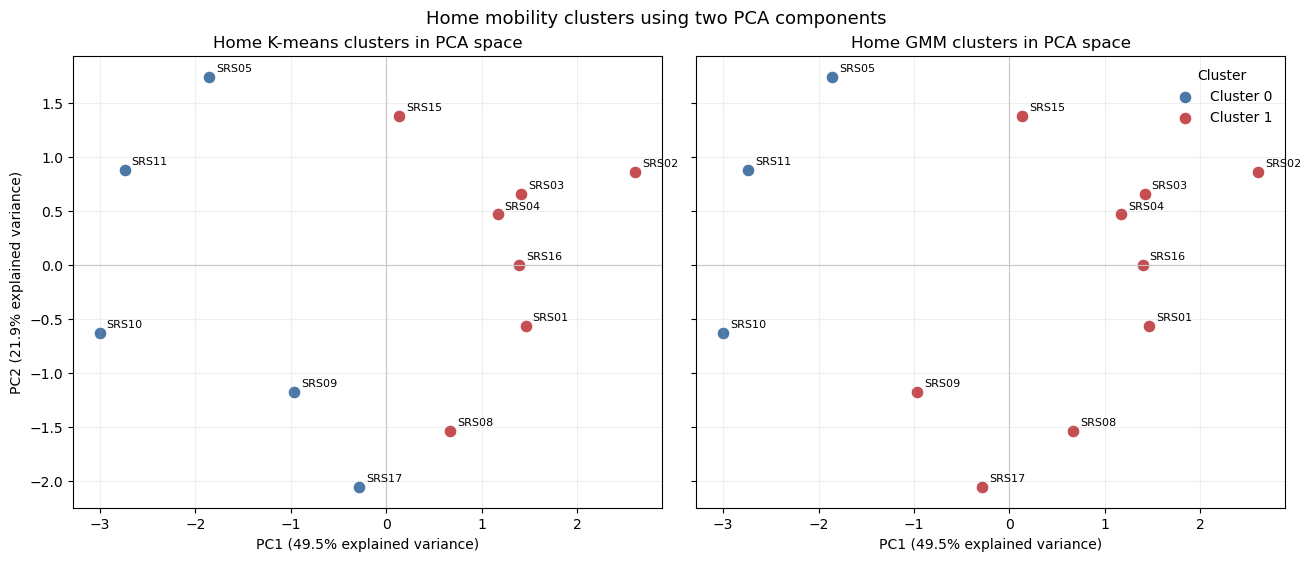

In [9]:
home_pca_two_components = PCA(n_components=2).fit_transform(home_scaled)
pc1_variance, pc2_variance = explained_variance[:2]
cluster_colors = {0: '#4C78A8', 1: '#C44E52'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True, constrained_layout=True)
models = [('K-means', 'kmeans_cluster'), ('GMM', 'gmm_cluster')]
for ax, (model_name, cluster_column) in zip(axes, models):
    for cluster, color in cluster_colors.items():
        mask = assignments[cluster_column].to_numpy() == cluster
        ax.scatter(
            home_pca_two_components[mask, 0], home_pca_two_components[mask, 1],
            s=85, color=color, edgecolor='white', linewidth=.8,
            label=f'Cluster {cluster}',
        )
    for point, participant in zip(home_pca_two_components, assignments['subject_id']):
        ax.annotate(participant, point, xytext=(5, 4), textcoords='offset points', fontsize=8)
    ax.axhline(0, color='#c7c7c7', linewidth=.8)
    ax.axvline(0, color='#c7c7c7', linewidth=.8)
    ax.set_xlabel(f'PC1 ({pc1_variance:.1f}% explained variance)')
    ax.set_title(f'Home {model_name} clusters in PCA space')
    ax.grid(alpha=.20)
axes[0].set_ylabel(f'PC2 ({pc2_variance:.1f}% explained variance)')
axes[1].legend(title='Cluster', frameon=False)
fig.suptitle('Home mobility clusters using two PCA components', fontsize=13)
plt.show()
